# Visualization Exercise Sheet

----------------------------------------------------------

In these short questions we will have you work with data from the GALAH spectroscopic survey (https://www.galah-survey.org) of stars in the Milky Way disk, and practice some visualization techniques to help analyze trends in the data.

You will find helpful documentation and examples to help you make the plots at the following graph galleries.
https://python-graph-gallery.com

https://matplotlib.org/stable/plot_types/index.html

**Download the data file 'galahamr.sav' located in the Moodle exercises page, which contains measurements of physical properties of ~7000 nearby stars.**

In [1]:
import numpy as np
from matplotlib import pyplot as plt

In [16]:
""" 
Set some defaults, most of all: LARGE fonts
"""
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'xx-large',
          'figure.figsize': (12, 7),
         'axes.labelsize': 'xx-large',
         'axes.titlesize':'xx-large',
         'xtick.labelsize':'xx-large',
         'ytick.labelsize':'xx-large'}
pylab.rcParams.update(params)

In [3]:
#Read in data set
from scipy.io import readsav
filepath = 'galahamr.sav'  #change this to the path on your computer where the file is stored
stars = readsav(filepath)  

In [4]:
#Pull out some attributes of the stars we want to look at and store them in arrays
logg = stars['f']['logg']  #surface gravity   
teff = stars['f']['teff']  #effective temperature
mass = stars['f']['massmean']  #mass
lum = mass**4.  #luminosity for stars 0.43 < Msun < 2
age = stars['f']['agemean'] #age
feh = stars['f']['__fe_h_'] #[Fe/H], a logarithmic Iron abundance
afe = stars['f']['__alpha_fe_']  #[Alpha/Fe], logarithmic relative abundance of alpha elements(O, Si, etc.) relative to Iron

### 1) Consider one version of the Hertzsprung-Russell diagram using effective temperature and surface gravity of the stars ( $T_{eff}$, log(g) ).  Make two types of plots of the stars, with clearly labeled axes and colorbars where suitable: 
* a) a scatter plot with the points colored by age 
* b) a 2D density plot using, e.g. the **kde** package along with the **pcolormesh** routine in matplotlib; or hist2d within matplotlib

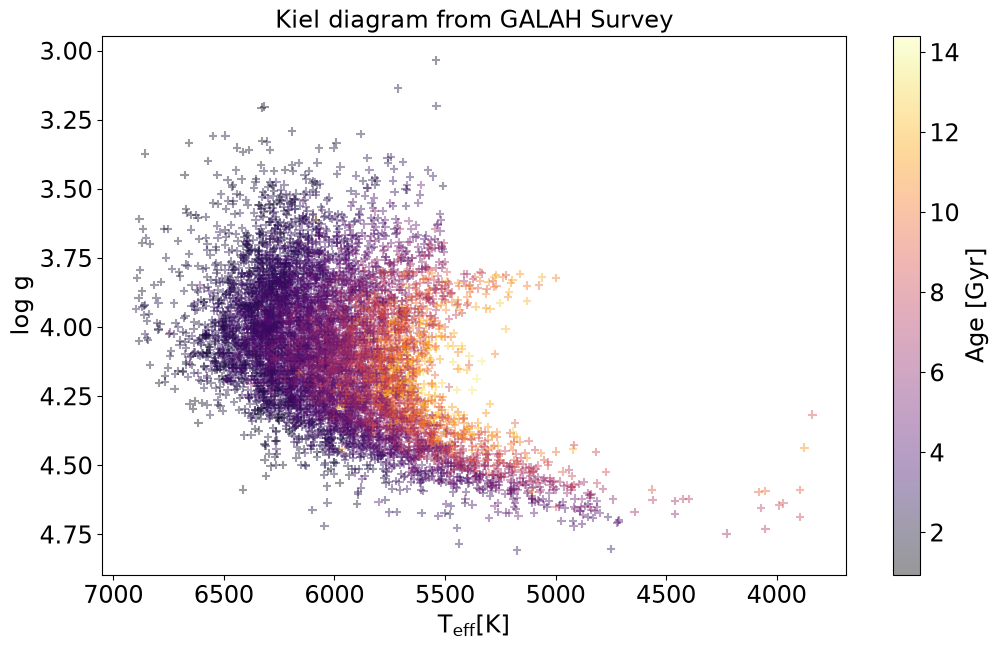

In [17]:
plt.figure()
plt.scatter(teff, logg, marker='+', c=age, cmap='inferno', alpha=0.4)
plt.colorbar().set_label(label='Age [Gyr]')
plt.xlabel(r'$\mathrm{T_{eff} [K]}$')
plt.ylabel('log g')                 # log g has no unit (log anything has no unit)
plt.gca().invert_xaxis()            # As it is HR diagram, we make temperature increase from right to left
plt.gca().invert_yaxis()            # Well, it is a Kiel diagram, and we also invert log g
plt.title('Kiel diagram from GALAH Survey')
plt.show()

<Figure size 1200x700 with 0 Axes>

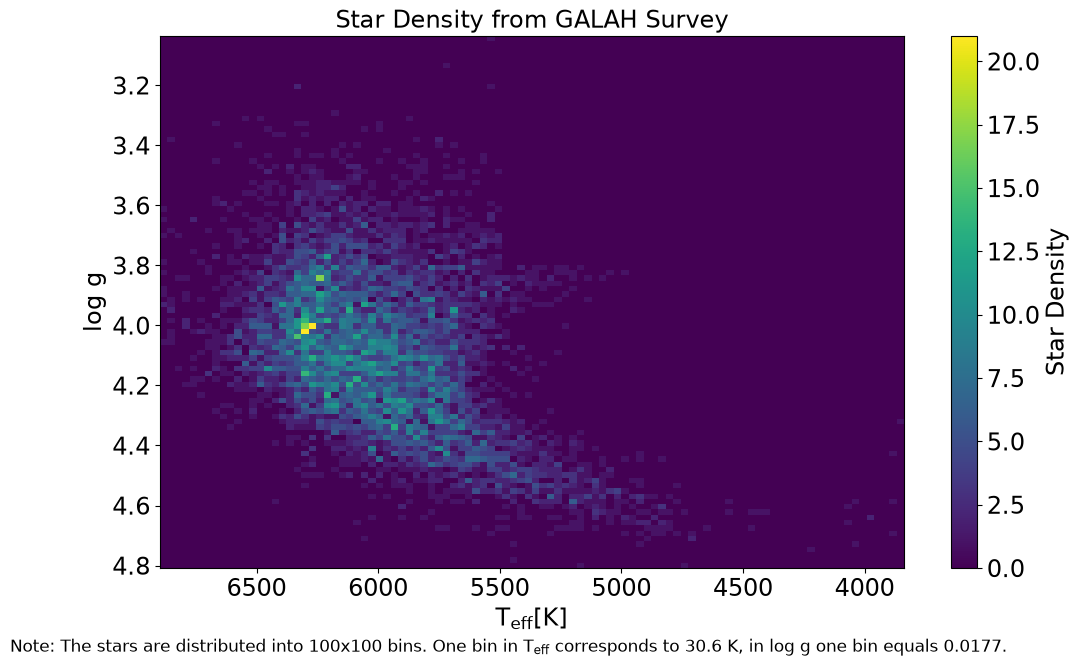

In [18]:
plt.figure()
fig, _ = plt.subplots()
bins = 100                                                      # you can play with the bin size
plt.hist2d(teff, logg, bins=bins, cmap='viridis')               # but 100 is a good compromise
plt.colorbar().set_label(label=f'Star Density')                 # a too big bin size makes the density disappear
plt.gca().invert_xaxis()
plt.xlabel(r'$\mathrm{T_{eff} [K]}$')
plt.gca().invert_yaxis()            
plt.ylabel('log g')
fig.subplots_adjust(bottom=0.12)                                # make some room for the foot note
plt.title('Star Density from GALAH Survey')

Note = f"Note: The stars are distributed into {bins}x{bins} bins. "    # f-string for incorporating variable easily
Note += r"One bin in $\mathrm{T_{eff}}$"                        # r-string for the LaTex formula, avoids escaping \ and others
Note += f" corresponds to {(teff.max() - teff.min())/bins:.1f} K"
Note += f", in log g one bin equals {(logg.max() - logg.min())/bins:.4f}."

fig.text(0,0, Note, fontsize=12)                                # place a text at the bottom left corner
plt.show()

### 2) Use a built-in, or hand-written routine to compute the running average of $T_{eff}$ as a function of $log(g)$.  Overplot this average approximation to the distribution of stars.  It should roughly subdivide the sample into cooler and hotter stars at a given value of $log(g)$.

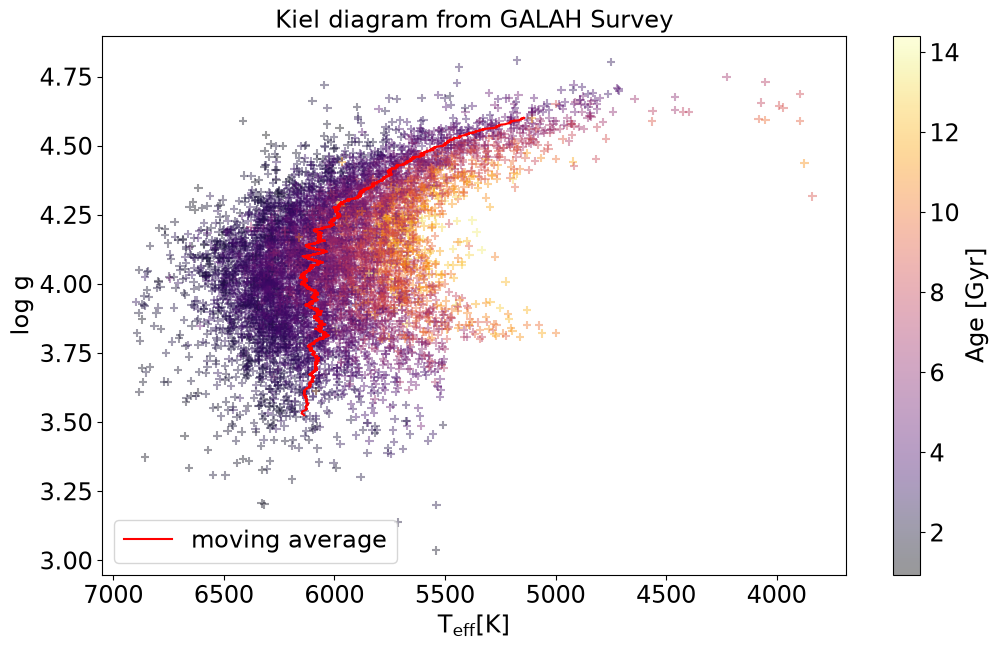

In [19]:
sort_idx = np.argsort(logg)                                         # as log g is our x-axis, we first create a sort index based on logg
logg_sorted = logg[sort_idx]                                        # and then sort logg
teff_sorted = teff[sort_idx]                                        # and teff along logg

window_size = 201                                                   # this is the sliding window for the running average, odd so that start_idx is a whoöe value
weights = np.ones(window_size) / window_size                        # starting with 200 the curve starts to look less nervous
teff_avg = np.convolve(teff_sorted, weights, mode='valid')          # convolution is a powerful instrument, used a lot in signal processing
                                                                    # but by convolution with a flat normalized window, we create a running average
start_idx = (window_size - 1) // 2                                  # by using the 'valid' method, we got as a result an array of length max(teff_sorted,weights) - min(teff_sorted, weights) + 1
logg_aligned = logg_sorted[start_idx : start_idx + len(teff_avg)]   # so we shift and slice our curve accordingly to match the original data
                                                                    # this is the reason, the red curve does not cover the complete logg range
plt.figure()
plt.scatter(teff, logg, marker='+', alpha=0.4, c=age, cmap='inferno')
plt.colorbar().set_label(label='Age [Gyr]')
plt.plot(teff_avg, logg_aligned, color='red', label='moving average')
plt.gca().invert_xaxis()
plt.ylabel('log g')
plt.xlabel(r'$\mathrm{T_{eff} [K]}$')
plt.ylabel('log g')
plt.legend()
plt.title('Kiel diagram from GALAH Survey')

plt.savefig('moving_avr.png')
plt.show()

#print(logg.size, teff.size, weights.size, teff_avg.size, logg_aligned.size)

### 3) [OPTIONAL]  Compute the mean and standard deviation ($\sigma$) of the ages of the cool and hot star sub-samples

* What percent of stars have an age that is within $1-\sigma$ of the mean ages of *both* the cool and hot star sub-samples?  e.g., the fraction of stars that have ages within
 
$(mean(age_{hot}) +\sigma(age_{hot}))$ $\leq age \leq$ $(mean(age_{cool}) -\sigma(age_{cool}))$

In [8]:
""" 
I use the same moving average of teff as calculated above for grouping the stars
But I need to add the age column and resize it to the teff_avg size
"""
age_sorted = age[sort_idx]
age_aligned = age_sorted[start_idx : start_idx + len(teff_avg)]
teff_aligned = teff_sorted[start_idx : start_idx + len(teff_avg)]

hot_mask = teff_aligned > teff_avg
cold_mask = teff_aligned < teff_avg

age_hot = age_aligned[hot_mask]
age_cold = age_aligned[cold_mask]

mean_hot = age_hot.mean()
sig_hot = age_hot.std()
mean_cold = age_cold.mean()
sig_cold = age_cold.std()
lower = mean_hot + sig_hot
upper = mean_cold - sig_cold
print(f'Mean of hot sample: {mean_hot:.2f} ± {sig_hot:.2f}, lower boundary: {lower:.2f}')
print(f'Mean of cold sample: {mean_cold:.2f} ± {sig_cold:.2f}, upper boundary: {upper:.2f}')

mask_hot_cold = (age_aligned >= lower) & (age_aligned <= upper)
hot_cold = age_aligned[mask_hot_cold]

perc = 100 * len(hot_cold) / len(age_aligned)

print(f'Percentage within one sigma of both samples: {perc:.2}')

# let us also check the overlapping area
lower = max(mean_hot - sig_hot, mean_cold - sig_cold)
upper = min(mean_hot + sig_hot, mean_cold + sig_cold)

mask_hot_cold = (age_aligned >= lower) & (age_aligned <= upper)
hot_cold = age_aligned[mask_hot_cold]

perc = 100 * len(hot_cold) / len(age_aligned)

print(f'Percentage within overlap of the two samples: {perc:.2f}')

Mean of hot sample: 3.67 ± 1.15, lower boundary: 4.82
Mean of cold sample: 6.87 ± 2.28, upper boundary: 4.59
Percentage within one sigma of both samples: 0.0
Percentage within overlap of the two samples: 3.48


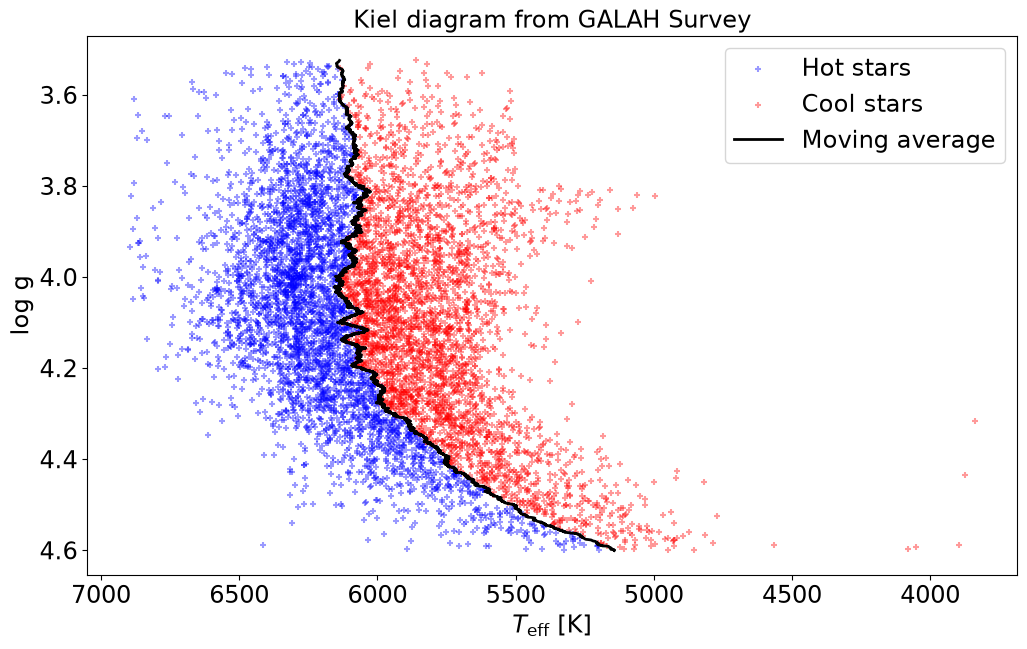

In [20]:
fig, ax = plt.subplots()

ax.scatter(teff_aligned[hot_mask], logg_aligned[hot_mask],
           s=20, color='blue', label='Hot stars', marker='+', alpha=0.4)

ax.scatter(teff_aligned[cold_mask], logg_aligned[cold_mask],
           s=20, color='red', label='Cool stars', marker='+', alpha=0.4)

ax.plot(teff_avg, logg_aligned, color='black', linewidth=2,
        label='Moving average')

ax.invert_xaxis()
ax.invert_yaxis()
ax.set_xlabel(r'$T_{\mathrm{eff}}$ [K]')
ax.set_ylabel('log g')
ax.legend()

plt.title('Kiel diagram from GALAH Survey')

plt.savefig('test_sep.png')

plt.show()

### 4) Create two versions of a *weighted* 2D density distribution of the sample of stars in the plane of **[Fe/H]** as a function of **age**:
* a) One where the density distribution is weighted by the mass of the stars
* b) One where the density distribution is weighted by the luminosity of the stars

Compute the weighted average metallicity and age for both cases and indicate them on the density distributions.

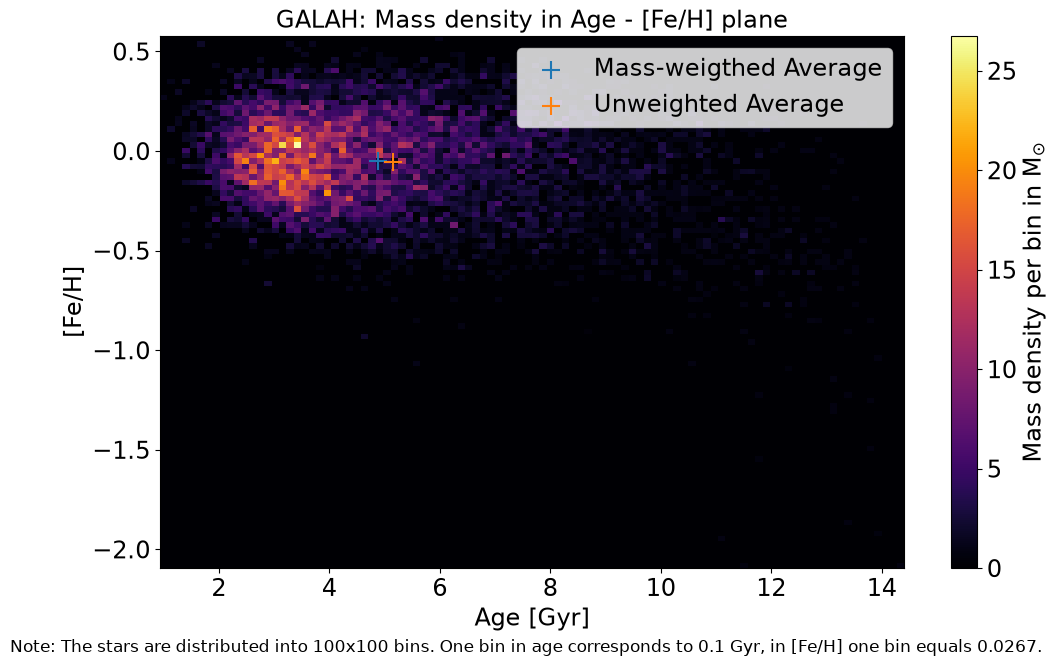

Mass range: 0.493504 2.083019
Mean mass: 1.142902175205208
Age-mass correlation: -0.6716340735774723
Unweighted age: 5.153536290687801
Mass-weighted age: 4.8887668267609214
Difference: -0.2647694639268794
Age std: 2.39104297764239
Mass std: 0.18843295215631187


In [21]:
""" 
I convert above script now to the object oriented version
The resulting plot is the same as in the old state interface
"""
fig, ax = plt.subplots()                                        # you can play with the bin size
bins = 100                                                      # but 100 is a good compromise
_, _, _, im = ax.hist2d(age, feh, weights=mass, bins=bins, cmap='inferno')  
                                                                # hist2d returns a lot, and we need only the last thing as a handle for attaching the cbar
                                                                # now we use the mass column for weights  
cbar = fig.colorbar(im, ax=ax)
cbar.set_label(label=r'Mass density per bin in $\mathrm{M_{\odot}}$')
ax.set_xlabel('Age [Gyr]')
ax.set_ylabel('[Fe/H]')
fig.subplots_adjust(bottom=0.12)                                # make some room for the foot note
age_mass_w = np.average(age, weights=mass)
feh_mass_w = np.average(feh, weights=mass)
ax.scatter(age_mass_w, feh_mass_w, marker='+', s=150, label='Mass-weigthed Average')
ax.scatter(age.mean(), feh.mean(), marker='+', s=150, label='Unweighted Average')
ax.legend()

ax.set_title('GALAH: Mass density in Age - [Fe/H] plane')

Note = f"Note: The stars are distributed into {bins}x{bins} bins. "    # f-string for incorporating variable easily
Note += r"One bin in age"                       
Note += f" corresponds to {(age.max() - age.min())/bins:.1f} Gyr"
Note += f", in [Fe/H] one bin equals {(feh.max() - feh.min())/bins:.4f}."

fig.text(0,0, Note, fontsize=12)                                # place a text at the bottom left corner
plt.savefig('mass_weigthed.png')
plt.show()

print("Mass range:", mass.min(), mass.max())
print("Mean mass:", mass.mean())
print("Age-mass correlation:", np.corrcoef(age, mass)[0, 1])

print("Unweighted age:", np.mean(age))
print("Mass-weighted age:", np.average(age, weights=mass))
print("Difference:", np.average(age, weights=mass) - np.mean(age))

print("Age std:", np.std(age))
print("Mass std:", np.std(mass))

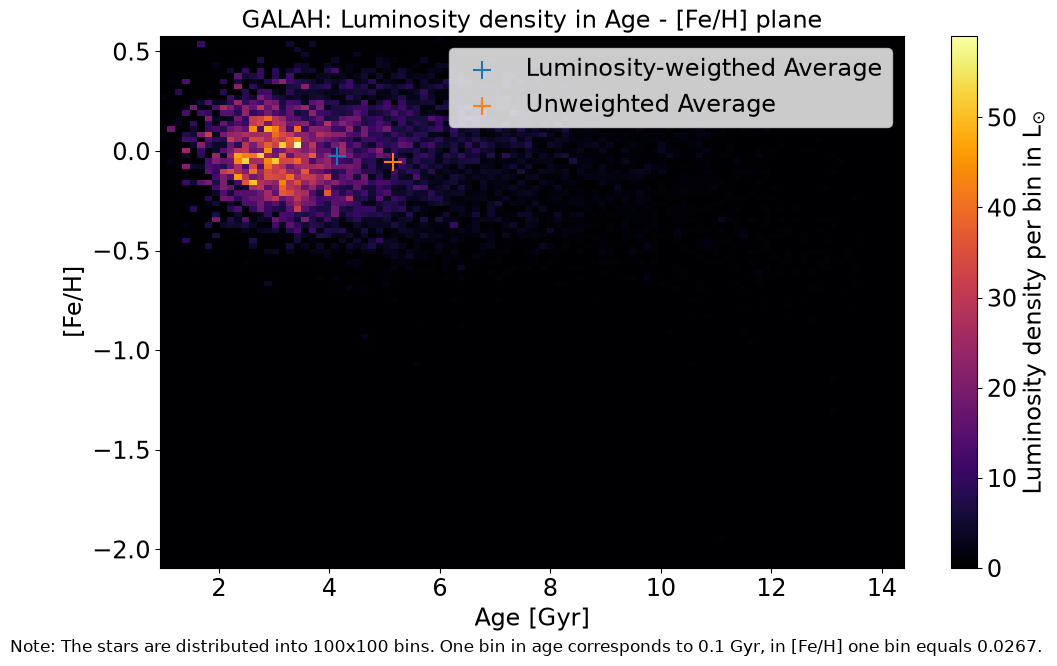

In [22]:
fig, ax = plt.subplots()                                        # you can play with the bin size
bins = 100                                                      # but 100 is a good compromise
_, _, _, im = ax.hist2d(age, feh, weights=lum, bins=bins, cmap='inferno')  
                                                                # hist2d returns a lot, and we need only the last thing as a handle for attaching the cbar
                                                                # now we use the lum column for weights  
cbar = fig.colorbar(im, ax=ax)
cbar.set_label(label=r'Luminosity density per bin in $\mathrm{L_{\odot}}$')
ax.set_xlabel('Age [Gyr]')
ax.set_ylabel('[Fe/H]')
fig.subplots_adjust(bottom=0.12)                                # make some room for the foot note

ax.set_title('GALAH: Luminosity density in Age - [Fe/H] plane')

age_lum_w = np.average(age, weights=lum)
feh_lum_w = np.average(feh, weights=lum)
ax.scatter(age_lum_w, feh_lum_w, marker='+', s=150, label='Luminosity-weigthed Average')
ax.scatter(age.mean(), feh.mean(), marker='+', s=150, label='Unweighted Average')
ax.legend()

Note = f"Note: The stars are distributed into {bins}x{bins} bins. "    # f-string for incorporating variable easily
Note += r"One bin in age"                       
Note += f" corresponds to {(age.max() - age.min())/bins:.1f} Gyr"
Note += f", in [Fe/H] one bin equals {(feh.max() - feh.min())/bins:.4f}."

fig.text(0,0, Note, fontsize=12)                                # place a text at the bottom left corner
plt.savefig('lum_weigthed.png')
plt.show()

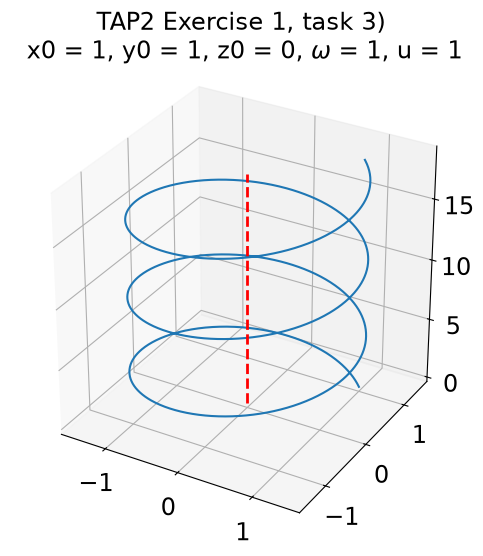

In [23]:
# Below is a lovely helix, which we needed for the TAP2 Exercise
# It is so nice, I added it here as Bonus

from math import pi
lam = np.linspace(0, 6*pi, 2000)

x0, y0, z0 = 1, 1, 0
om = 1
u = 1

x = x0 * np.cos(om * lam) - y0 * np.sin(om * lam)
y = x0 * np.sin(om * lam) + y0 * np.cos(om * lam)
z = u * lam + z0

fig = plt.figure(figsize=(6,6))
ax = fig.add_subplot(projection='3d')
#ax.set_box_aspect((1, 1, 2))
ax.set_aspect('equal')
ax.plot(x, y, z)
ax.plot(
    [0, 0],
    [0, 0],
    [z.min(), z.max()],
    color='red',
    linestyle='--',
    linewidth=2
)
title = f'TAP2 Exercise 1, task 3)\n x0 = {x0}, y0 = {y0}, z0 = {z0}, ' + \
r'$\omega$ ' + f'= {om}, u = {u}'
ax.set_title(title)

plt.savefig('tap.pdf')
plt.show()